In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import scipy

df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/AB_NYC.csv", index_col=0)

In [ ]:
df

,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
id,,,,,,,,,,,,,,,
2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149.0,1,9,2018-10-19,0.21,6,365
2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225.0,1,45,2019-05-21,0.38,2,355
3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150.0,3,0,NaN,NaN,1,365
3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89.0,1,270,2019-07-05,4.64,1,194
5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80.0,10,9,2018-11-19,0.10,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36484665,Charming one bedroom - newly renovated rowhouse,8232441,Sabrina,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70.0,2,0,NaN,NaN,2,9
36485057,Affordable room in Bushwick/East Williamsburg,6570630,Marisol,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40.0,4,0,NaN,NaN,2,36
36485431,Sunny Studio at Historical Neighborhood,23492952,Ilgar & Aysel,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115.0,10,0,NaN,NaN,1,27


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 48895 entries, 2539 to 36487245
Data columns (total 15 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   name                            48879 non-null  object 
 1   host_id                         48895 non-null  int64  
 2   host_name                       48874 non-null  object 
 3   neighbourhood_group             48895 non-null  object 
 4   neighbourhood                   48895 non-null  object 
 5   latitude                        48895 non-null  float64
 6   longitude                       48895 non-null  float64
 7   room_type                       48895 non-null  object 
 8   price                           48874 non-null  float64
 9   minimum_nights                  48895 non-null  int64  
 10  number_of_reviews               48895 non-null  int64  
 11  last_review                     38843 non-null  object 
 12  reviews_per_month              

In [ ]:
print(f"Alojamientos unicos: {len(df.index.unique())}")
print(f"Hosts unicos: {len(df.host_id.unique())}")

Alojamientos unicos: 48895
Hosts unicos: 37457


In [ ]:
# Reseteamos id para que sean indices mas pequeños
df = df.reset_index(drop=True)

In [ ]:
df

,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149.0,1,9,2018-10-19,0.21,6,365
1,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225.0,1,45,2019-05-21,0.38,2,355
2,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150.0,3,0,NaN,NaN,1,365
3,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89.0,1,270,2019-07-05,4.64,1,194
4,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80.0,10,9,2018-11-19,0.10,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48890,Charming one bedroom - newly renovated rowhouse,8232441,Sabrina,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70.0,2,0,NaN,NaN,2,9
48891,Affordable room in Bushwick/East Williamsburg,6570630,Marisol,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40.0,4,0,NaN,NaN,2,36
48892,Sunny Studio at Historical Neighborhood,23492952,Ilgar & Aysel,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115.0,10,0,NaN,NaN,1,27
48893,43rd St. Time Square-cozy single bed,30985759,Taz,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55.0,1,0,NaN,NaN,6,2


In [ ]:
# Descriptivo nominales
df.describe(include="object")

,name,host_name,neighbourhood_group,neighbourhood,room_type,last_review
count,48879,48874,48895,48895,48895,38843
unique,47905,11452,5,221,3,1764
top,Hillside Hotel,Michael,Manhattan,Williamsburg,Entire home/apt,2019-06-23
freq,18,417,21661,3920,25409,1413


In [ ]:
# Las columnas name y host_name son irrelevantes para el exploratorio
# Las descartamos pero guardamos su referencia por index

apartment_details = df[["name", "host_name", "host_id"]].copy()
df = df.drop(columns=["name", "host_name", "host_id"])

In [ ]:
# Descriptivo numericas
df.describe()

,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,48895.000000,48895.000000,48874.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,40.728949,-73.952170,152.720567,7.029962,23.274466,1.373221,7.143982,112.781327
std,0.054530,0.046157,240.205759,20.510550,44.550582,1.680442,32.952519,131.622289
min,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,40.723070,-73.955680,105.500000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


# Análisis de outliers

In [ ]:
# Añadimos el IQR a las numericas, descartando el host_id
desc = df.describe()
desc.loc["IQR"] = desc.loc["75%"] - desc.loc["25%"]
desc.loc["min_outlier"] = desc.loc["25%"] - 1.5*desc.loc["IQR"]
desc.loc["max_outlier"] = desc.loc["75%"] + 1.5*desc.loc["IQR"]
desc

,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,48895.000000,48895.000000,48874.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,40.728949,-73.952170,152.720567,7.029962,23.274466,1.373221,7.143982,112.781327
std,0.054530,0.046157,240.205759,20.510550,44.550582,1.680442,32.952519,131.622289
min,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,40.723070,-73.955680,105.500000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000
IQR,0.073015,0.046795,106.000000,4.000000,23.000000,1.830000,1.000000,227.000000
min_outlier,40.580578,-74.053263,-90.000000,-5.000000,-33.500000,-2.555000,-0.500000,-340.500000


In [ ]:
# Candidatos a outlier por el método IQR

candidates_iqr = {}
for col in desc.columns:
  candidates_iqr[col] = df[(df[col] < desc.loc["min_outlier", col]) | (df[col] > desc.loc["max_outlier", col])].copy()
  print(f"Candidatos {col}: {len(candidates_iqr[col])}")

Candidatos latitude: 425
Candidatos longitude: 2833
Candidatos price: 2972
Candidatos minimum_nights: 6607
Candidatos number_of_reviews: 6021
Candidatos reviews_per_month: 1793
Candidatos calculated_host_listings_count: 7081
Candidatos availability_365: 0


In [ ]:
lat1 = df.nlargest(1, columns="latitude")[["longitude", "latitude"]]
lat0 = df.nsmallest(1, columns="latitude")[["longitude", "latitude"]]
lon1 = df.nlargest(1, columns="longitude")[["longitude", "latitude"]]
lon0 = df.nsmallest(1, columns="longitude")[["longitude", "latitude"]]

[lat1, lat0, lon1, lon0]

[       longitude  latitude
 48029  -73.89389  40.91306,
        longitude  latitude
 14119  -74.24084  40.49979,
        longitude  latitude
 10920  -73.71299  40.73351,
        longitude  latitude
 45652  -74.24442  40.50943]

In [ ]:
# Para longitud y latitud no tiene sentido descartar por IQR
# Veamos los valores extremos

lat1 = df.nlargest(1, columns="latitude").index
lat0 = df.nsmallest(1, columns="latitude").index
lon1 = df.nlargest(1, columns="longitude").index
lon0 = df.nsmallest(1, columns="longitude").index

indexes = [x[0] for x in [lat1, lat0, lon1, lon0]]

spatial_outliers = df.iloc[indexes, :].loc[:, ["longitude", "latitude"]]

In [ ]:
spatial_outliers

,longitude,latitude
48029,-73.89389,40.91306
14119,-74.24084,40.49979
10920,-73.71299,40.73351
45652,-74.24442,40.50943


In [ ]:
import requests
import zipfile
import os
import geopandas as gpd
from shapely.geometry import Point, Polygon

/usr/local/lib/python3.12/dist-packages/pyproj/crs/crs.py:143: FutureWarning: '+init=<authority>:<code>' syntax is deprecated. '<authority>:<code>' is the preferred initialization method. When making the change, be mindful of axis order changes: https://pyproj4.github.io/pyproj/stable/gotchas.html#axis-order-changes-in-proj-6
  in_crs_string = _prepare_from_proj_string(in_crs_string)


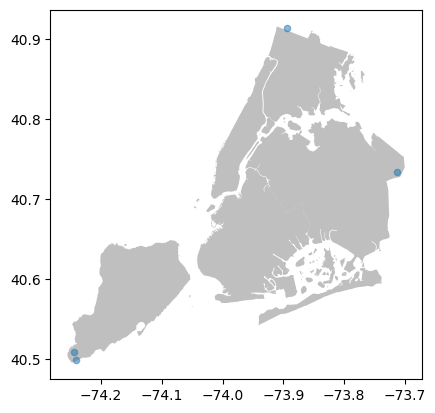

In [ ]:
# peticion get a geodata nyc
res = requests.get("https://www1.nyc.gov/assets/planning/download/zip/data-maps/open-data/nybb_20b.zip")

# guardamos el contenido en zip
with open("nyc_map.zip", "wb") as fp:
  fp.write(res.content)

# descomprimimos
dest_path = "/content/drive/MyDrive/Colab Notebooks/nyc_map"
with zipfile.ZipFile('nyc_map.zip', 'r') as zip_ref:
    zip_ref.extractall(path=dest_path)

# extraemos el nombre de fichero .shp
shp_file = [f for f in os.listdir(dest_path) if ".shp" in f][0]

# creamos la silueta del mapa
street_map = gpd.read_file(f"{dest_path}/{shp_file}")

# Añadimos los puntos sobre la geometria
# El EPSG 4326 corresponde al convencional sistema WGS84 empleado para la representación de la cartografía a nivel mundial
crs = {"init": "epsg:4326"}

geometry = [Point(xy) for xy in zip(spatial_outliers.longitude, spatial_outliers.latitude)]

# creamos el GeoPandas dataframe
geo_df = gpd.GeoDataFrame(spatial_outliers,
 crs = crs,
 geometry = geometry)

# dibujamos la silueta del mapa y los puntos por encima
fig, ax = plt.subplots()
street_map.plot(ax=ax, alpha=0.5, color="grey")
geo_df.plot(ax=ax, alpha=0.5, markersize=20)
plt.show()

/usr/local/lib/python3.12/dist-packages/pyproj/crs/crs.py:143: FutureWarning: '+init=<authority>:<code>' syntax is deprecated. '<authority>:<code>' is the preferred initialization method. When making the change, be mindful of axis order changes: https://pyproj4.github.io/pyproj/stable/gotchas.html#axis-order-changes-in-proj-6
  in_crs_string = _prepare_from_proj_string(in_crs_string)


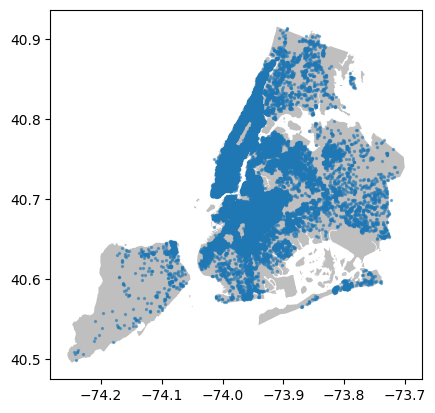

In [ ]:
# Nuevo mapa con todos los puntos, para ver si hay outliers dentro del cuadrado
geometry = [Point(xy) for xy in zip(df.longitude, df.latitude)]

# creamos el GeoPandas dataframe
geo_df = gpd.GeoDataFrame(df,
 crs = crs,
 geometry = geometry)

# dibujamos la silueta del mapa y los puntos por encima
fig, ax = plt.subplots()
street_map.plot(ax=ax, alpha=0.5, color="grey")
geo_df.plot(ax=ax, alpha=0.5, markersize=2)
plt.show()

**Por lo tanto mantenemos todos los datos asociados a latitud y longitud**

# Analisis precio

In [ ]:
candidates_iqr["price"].sort_values("price")

,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
19462,Manhattan,Upper West Side,40.79772,-73.96213,Entire home/apt,335.0,4,59,2019-05-12,1.89,1,263
12262,Brooklyn,Bedford-Stuyvesant,40.68282,-73.92934,Entire home/apt,335.0,2,21,2019-06-16,0.53,1,304
44433,Brooklyn,Crown Heights,40.67978,-73.96231,Entire home/apt,335.0,2,1,2019-07-01,1.00,3,365
44761,Manhattan,Upper West Side,40.80249,-73.96588,Entire home/apt,335.0,5,5,2019-06-24,3.19,1,221
10398,Manhattan,Midtown,40.76633,-73.98145,Entire home/apt,335.0,30,0,NaN,NaN,121,201
...,...,...,...,...,...,...,...,...,...,...,...,...
12342,Manhattan,Lower East Side,40.71355,-73.98507,Private room,9999.0,99,6,2016-01-01,0.14,1,83
40433,Manhattan,Lower East Side,40.71980,-73.98566,Entire home/apt,9999.0,30,0,NaN,NaN,1,365
29238,Manhattan,Upper West Side,40.77213,-73.98665,Entire home/apt,10000.0,30,0,NaN,NaN,1,83
9151,Queens,Astoria,40.76810,-73.91651,Private room,10000.0,100,2,2016-02-13,0.04,1,0


<Axes: >

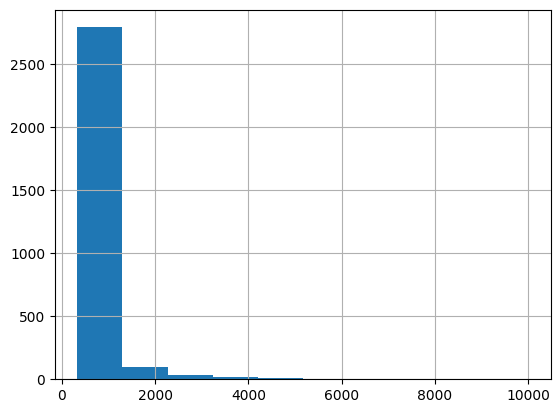

In [ ]:
candidates_iqr["price"]["price"].hist()

<Axes: >

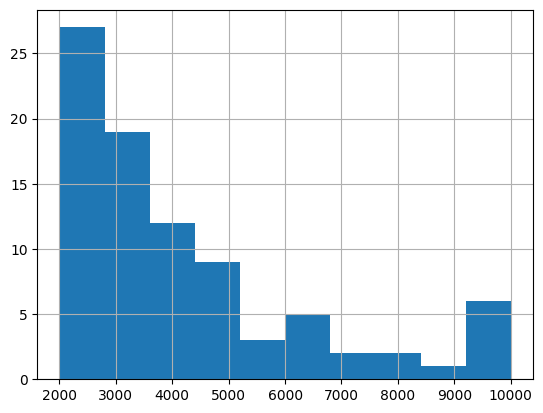

In [ ]:
candidates_iqr["price"].loc[df.price > 2000, "price"].hist()

In [ ]:
# Vamos a buscar si alguna de las caras tiene características de casa barata

candidates_iqr["price"].loc[
    ((candidates_iqr["price"]["number_of_reviews"] == 0) |
    (candidates_iqr["price"]["availability_365"] == 0) |
    (candidates_iqr["price"]["room_type"] != "Entire home/apt") |
     (candidates_iqr["price"]["minimum_nights"] > 30)) &
    (candidates_iqr["price"]["price"] > 2000)]

,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
946,Manhattan,Upper West Side,40.80142,-73.96931,Private room,3000.0,7,0,NaN,NaN,1,365
1862,Brooklyn,Prospect Heights,40.67919,-73.97191,Entire home/apt,4000.0,4,0,NaN,NaN,1,83
3695,Manhattan,Upper West Side,40.79476,-73.97299,Entire home/apt,4000.0,1,0,NaN,NaN,1,0
3720,Manhattan,Little Italy,40.71895,-73.99793,Entire home/apt,5250.0,1,0,NaN,NaN,1,0
3774,Brooklyn,Clinton Hill,40.68766,-73.96439,Entire home/apt,6500.0,1,0,NaN,NaN,1,0
3782,Manhattan,Kips Bay,40.74215,-73.98018,Entire home/apt,2750.0,1,0,NaN,NaN,1,0
3785,Manhattan,Greenwich Village,40.73350,-73.99834,Entire home/apt,2500.0,1,0,NaN,NaN,1,0
3788,Manhattan,East Village,40.73323,-73.98859,Entire home/apt,3750.0,1,0,NaN,NaN,1,0
4345,Brooklyn,Bedford-Stuyvesant,40.69572,-73.95731,Private room,5000.0,6,10,2016-01-02,0.16,1,363
5839,Manhattan,Upper West Side,40.76810,-73.98377,Entire home/apt,2695.0,1,0,NaN,NaN,1,0


In [ ]:
outliers_up_price = candidates_iqr["price"].loc[
    (((candidates_iqr["price"]["number_of_reviews"] == 0) |
    (candidates_iqr["price"]["availability_365"] == 0) |
    (candidates_iqr["price"]["room_type"] != "Entire home/apt") |
     (candidates_iqr["price"]["minimum_nights"] > 30)) &
    (candidates_iqr["price"]["price"] > 2000)) |
    (candidates_iqr["price"]["price"] > 5000)].index

In [ ]:
outliers_up_price

Index([  946,  1862,  3537,  3695,  3720,  3774,  3782,  3785,  3788,  4345,
        4377,  5839,  6530,  9151, 12342, 14573, 15390, 15560, 17692, 17811,
       21821, 22353, 22373, 22992, 24286, 24477, 25825, 26739, 28727, 28945,
       28946, 28947, 29238, 29662, 29663, 29664, 29665, 29666, 30260, 30268,
       34851, 37194, 37450, 37864, 38358, 38498, 38947, 39243, 39846, 40433,
       40586, 41216, 41770, 42523, 42736, 43009, 43670, 44034, 45666, 45710,
       45867, 46614, 48043, 48304],
      dtype='int64')

<Axes: >

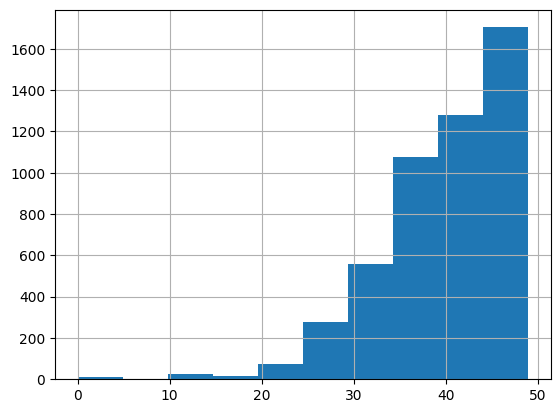

In [ ]:
# Vamos a ver la distribucion de los precios bajos
df.loc[df.price < 50, "price"].hist()

<Axes: >

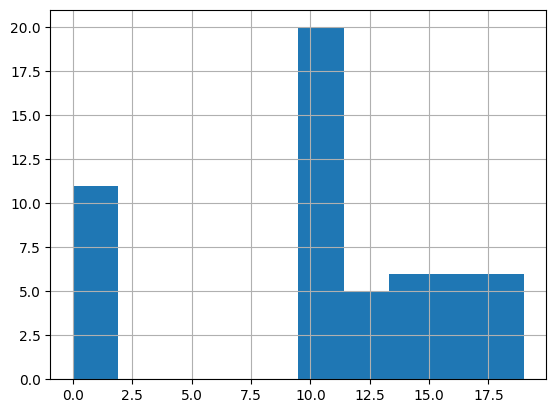

In [ ]:
# Vamos a ver la distribucion de los precios bajos
df.loc[df.price < 20, "price"].hist()

In [ ]:
outliers_down_price = df[df.price <= 10].index
outliers_down_price

Index([ 2860, 21700, 22261, 22287, 22835, 23161, 23256, 24100, 25433, 25634,
       25753, 25778, 25794, 25795, 25796, 26259, 26841, 26866, 27972, 31066,
       31407, 32810, 33225, 33505, 34446, 35386, 35601, 47218],
      dtype='int64')

In [ ]:
outliers_price = list(outliers_up_price) + list(outliers_down_price)

In [ ]:
len(outliers_price)

92

# Analisis de noches minimas

<Axes: >

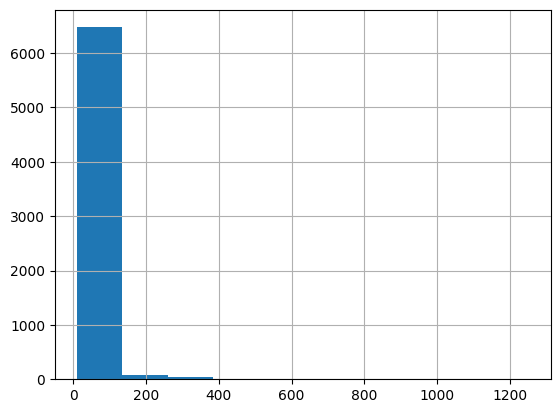

In [ ]:
# El minimo es 1 y es logico // Vamos a estudiar el maximo
candidates_iqr["minimum_nights"]["minimum_nights"].hist()

<Axes: >

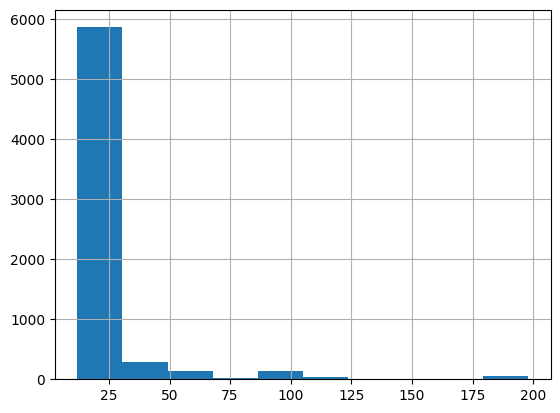

In [ ]:
candidates_iqr["minimum_nights"].loc[df.minimum_nights < 200, "minimum_nights"].hist()

<Axes: >

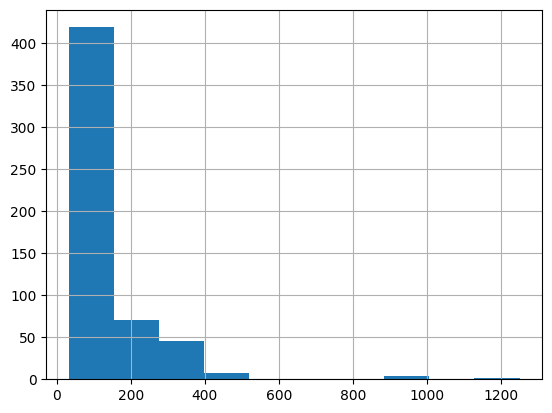

In [ ]:
# Veamos que sucede por encima de 31 dias
candidates_iqr["minimum_nights"].loc[df.minimum_nights > 31, "minimum_nights"].hist()

In [ ]:
outliers_min_nights = list(candidates_iqr["minimum_nights"].loc[df.minimum_nights > 31].index)
len(outliers_min_nights)

546

# Analisis reviews

<Axes: >

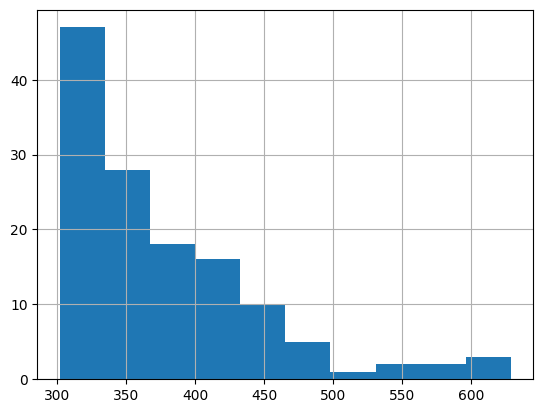

In [ ]:
candidates_iqr["number_of_reviews"].loc[df.number_of_reviews > 300, "number_of_reviews"].hist()

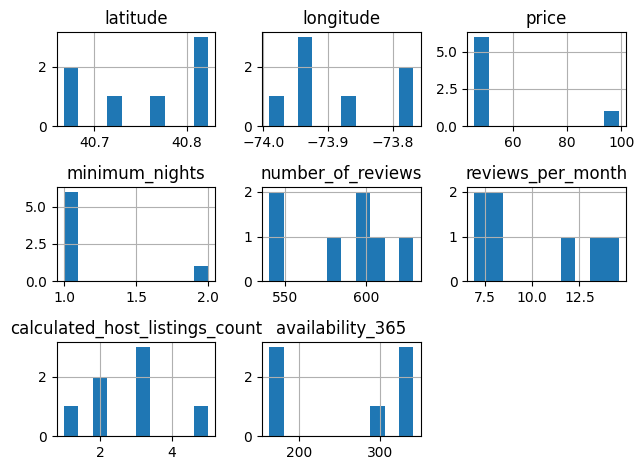

In [ ]:
# que pasa en esos casos raros?
candidates_iqr["number_of_reviews"].loc[df.number_of_reviews > 530, :].hist()
plt.tight_layout()

## Análisis de reviews per month

<Axes: >

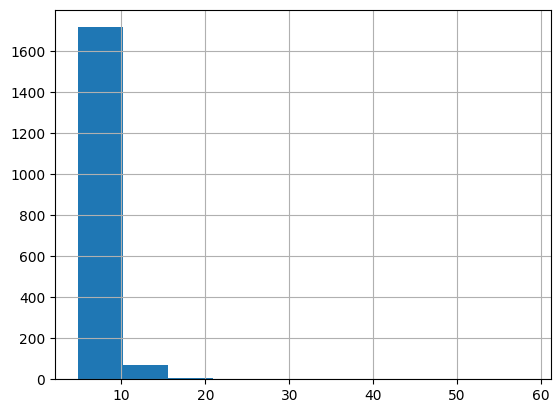

In [ ]:
candidates_iqr["reviews_per_month"]["reviews_per_month"].hist()

<Axes: >

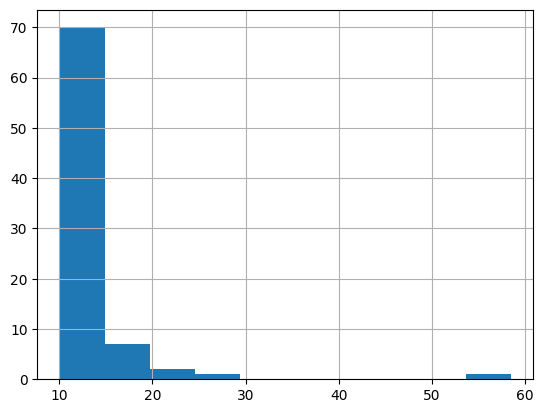

In [ ]:
candidates_iqr["reviews_per_month"].loc[df["reviews_per_month"] > 10, "reviews_per_month"].hist()

In [ ]:
outliers_reviews_month = list(df[df.reviews_per_month > 30].index)
len(outliers_reviews_month)

1

<Axes: >

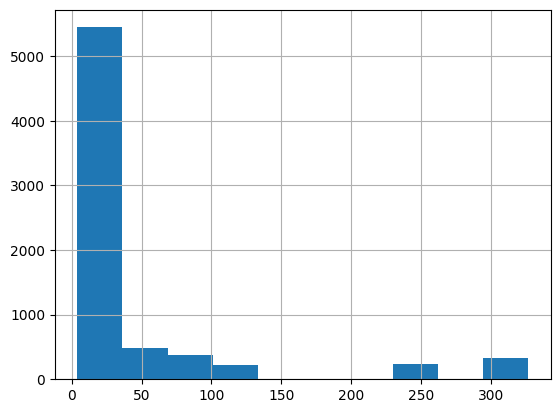

In [ ]:
candidates_iqr["calculated_host_listings_count"]["calculated_host_listings_count"].hist()

<Axes: >

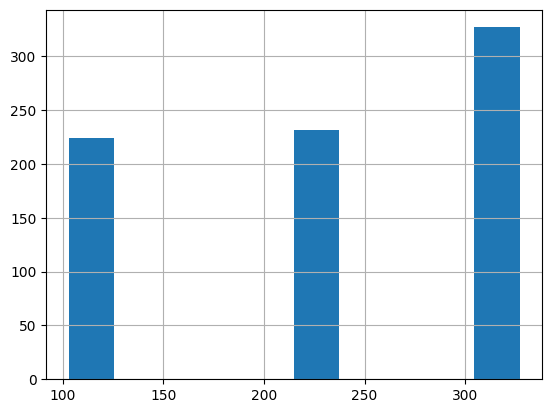

In [ ]:
candidates_iqr["calculated_host_listings_count"].loc[df["calculated_host_listings_count"] > 100, "calculated_host_listings_count"].hist()

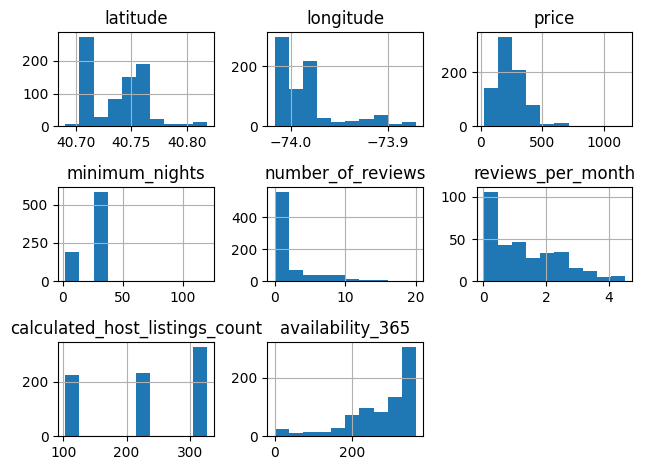

In [ ]:
candidates_iqr["calculated_host_listings_count"].loc[df["calculated_host_listings_count"] > 100, :].hist()
plt.tight_layout()

In [ ]:
# Muy raro las noches minimas
df.loc[df["calculated_host_listings_count"] > 100, "minimum_nights"].mean()

np.float64(23.856960408684547)

In [ ]:
# Viendo esa distribucion tan rara, los descartamos todos

outliers_listings = list(df[df["calculated_host_listings_count"] > 100].index)
len(outliers_listings)

783

In [ ]:
# Availability

print(f"Alojamientos con 0 noches disponibles: {len(df[df.availability_365 == 0])}")
print(f"Alojamientos con todas noches disponibles: {len(df[df.availability_365 == 365])}")

Alojamientos con 0 noches disponibles: 17533
Alojamientos con todas noches disponibles: 1295


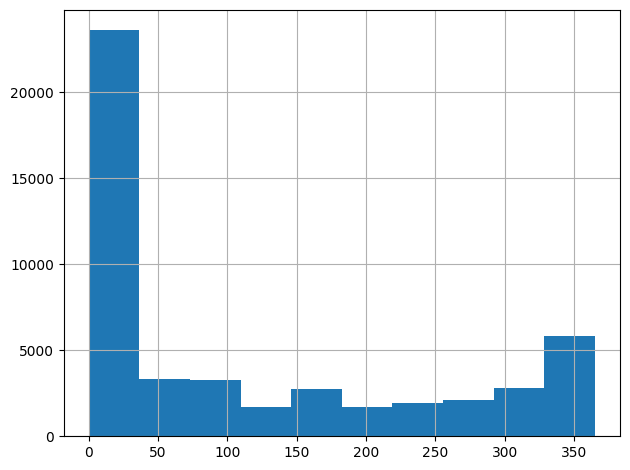

In [ ]:
df.loc[df.availability_365 <= 1000, "availability_365"].hist()
plt.tight_layout()

In [ ]:
outliers_availability = list(df[df.availability_365 == 0].index)
len(outliers_availability)

17533

In [ ]:
all_outliers = outliers_min_nights + outliers_listings + outliers_availability + outliers_price + outliers_reviews_month
len(set(all_outliers))

18775

In [ ]:
df = df[~df.index.isin(all_outliers)]

In [ ]:
df

,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,Brooklyn,Kensington,40.64749,-73.97237,Private room,149.0,1,9,2018-10-19,0.21,6,365
1,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225.0,1,45,2019-05-21,0.38,2,355
2,Manhattan,Harlem,40.80902,-73.94190,Private room,150.0,3,0,NaN,NaN,1,365
3,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89.0,1,270,2019-07-05,4.64,1,194
5,Manhattan,Murray Hill,40.74767,-73.97500,Entire home/apt,200.0,3,74,2019-06-22,0.59,1,129
...,...,...,...,...,...,...,...,...,...,...,...,...
48890,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70.0,2,0,NaN,NaN,2,9
48891,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40.0,4,0,NaN,NaN,2,36
48892,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115.0,10,0,NaN,NaN,1,27
48893,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55.0,1,0,NaN,NaN,6,2


# Analisis nulos

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 30120 entries, 0 to 48894
Data columns (total 13 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   host_id                         30120 non-null  int64  
 1   neighbourhood_group             30120 non-null  object 
 2   neighbourhood                   30120 non-null  object 
 3   latitude                        30120 non-null  float64
 4   longitude                       30120 non-null  float64
 5   room_type                       30120 non-null  object 
 6   price                           30103 non-null  float64
 7   minimum_nights                  30120 non-null  int64  
 8   number_of_reviews               30120 non-null  int64  
 9   last_review                     25585 non-null  object 
 10  reviews_per_month               25585 non-null  float64
 11  calculated_host_listings_count  30120 non-null  int64  
 12  availability_365                

In [ ]:
# NO HAY APARTAMENTOS CON REVIEWS Y A SU VEZ REVIEWS_PER_MONTH NULAS
df.loc[df.reviews_per_month.isna() & (df.number_of_reviews > 0)]

,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365


In [ ]:
# Descartamos los nulos en precio porque es la variable que queremos analizar
# Descartamos columna last_review -> debería haber correlación total con number_of_reviews
# En reviews per month, asignamos un 0 a los null

df = df.drop(columns="last_review")
df = df[~df.price.isna()]
df.loc[df.reviews_per_month.isna(), "reviews_per_month"] = 0.0

df

,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
0,Brooklyn,Kensington,40.64749,-73.97237,Private room,149.0,1,9,0.21,6,365
1,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225.0,1,45,0.38,2,355
2,Manhattan,Harlem,40.80902,-73.94190,Private room,150.0,3,0,0.00,1,365
3,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89.0,1,270,4.64,1,194
5,Manhattan,Murray Hill,40.74767,-73.97500,Entire home/apt,200.0,3,74,0.59,1,129
...,...,...,...,...,...,...,...,...,...,...,...
48890,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70.0,2,0,0.00,2,9
48891,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40.0,4,0,0.00,2,36
48892,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115.0,10,0,0.00,1,27
48893,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55.0,1,0,0.00,6,2


In [ ]:
df.to_json("/content/drive/MyDrive/Colab Notebooks/clean_dataset.json", orient="records")

In [ ]:
df = pd.read_json("/content/drive/MyDrive/Colab Notebooks/clean_dataset.json", orient="records")

In [ ]:
df

,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
0,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,0.21,6,365
1,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,0.38,2,355
2,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,0.00,1,365
3,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,4.64,1,194
4,Manhattan,Murray Hill,40.74767,-73.97500,Entire home/apt,200,3,74,0.59,1,129
...,...,...,...,...,...,...,...,...,...,...,...
30098,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70,2,0,0.00,2,9
30099,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40,4,0,0.00,2,36
30100,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115,10,0,0.00,1,27
30101,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55,1,0,0.00,6,2


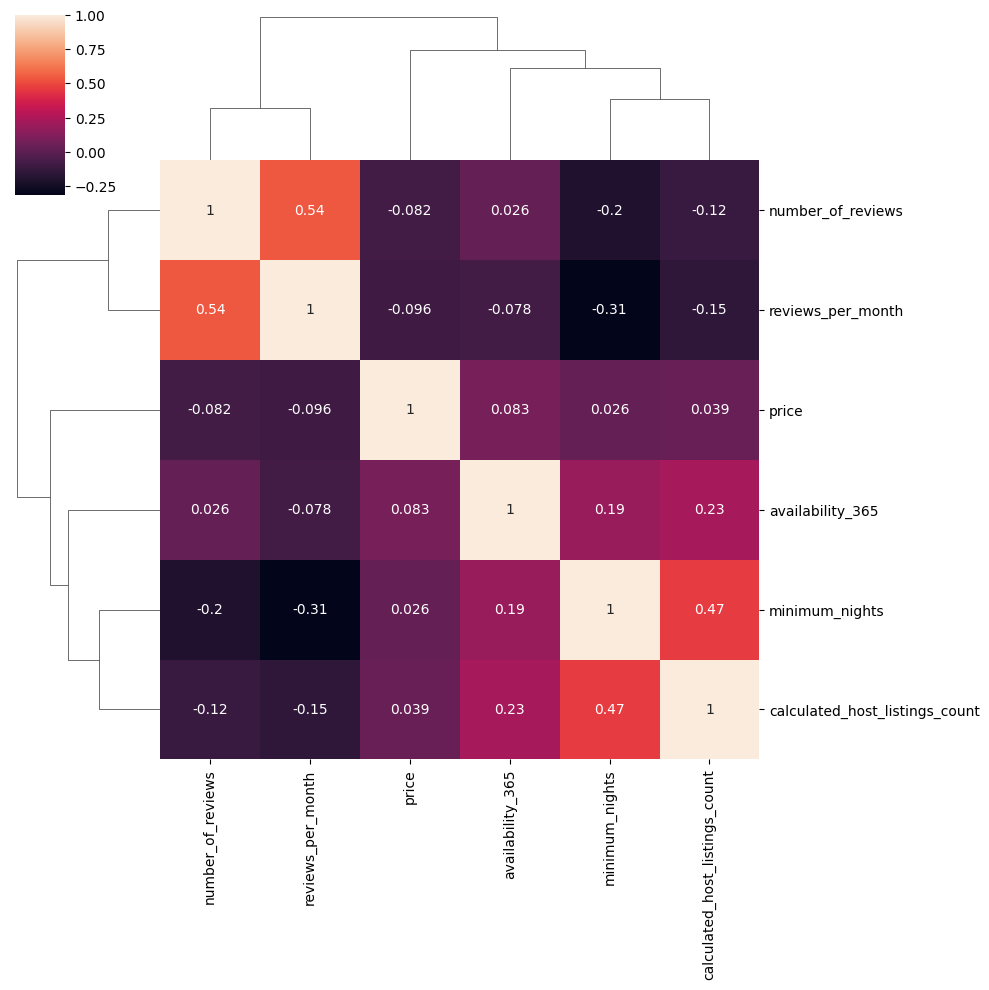

In [ ]:
sns.clustermap(df.select_dtypes(np.number).drop(columns=["latitude", "longitude"]).corr(), annot=True)

Análisis de correlación:


*   Nº reviews y reviews por mes tienen alta correlación positiva. Normal, puesto que los apartamentos con mas reviews tendrán una mayor tasa de aceptación y por tanto recibirán mas reviews mensuales.
*   Alta correlación entre alojamientos por host, minimo de noches y disponibilidad. Esta no es tan obvia, pero parece indicar los usuarios con varios apartamentos, suelen alquilarlo a medio plazo, pero sin mucho exito.
*   Ninguna variable tiene alta correlación con el precio, la más es la disponibilidad. Parece tener sentido que los apartamentos más caros estén tengan más disponibilidad





<Axes: xlabel='price', ylabel='availability_365'>

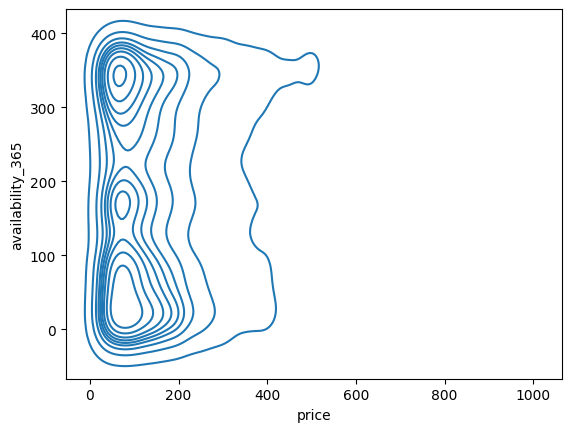

In [ ]:
sns.kdeplot(df[df.price < 1000], x="price", y="availability_365")

<Axes: xlabel='price', ylabel='reviews_per_month'>

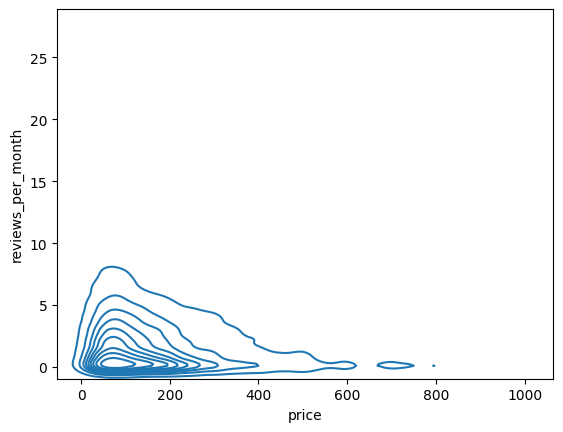

In [ ]:
sns.kdeplot(df[df.price < 1000], x="price", y="reviews_per_month")

Análisis de precio frente categóricas

<Axes: xlabel='room_type', ylabel='price'>

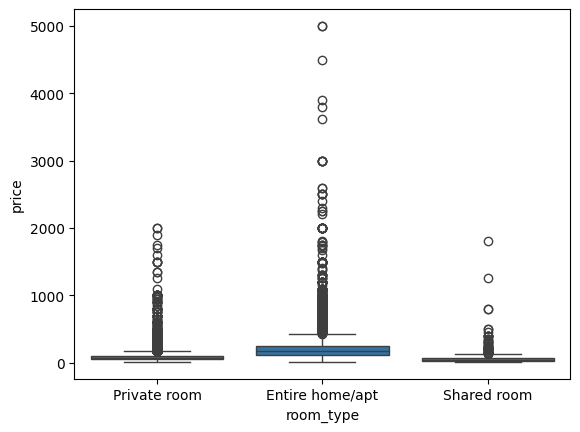

In [ ]:
sns.boxplot(df, x="room_type", y="price")

Se ve como a partir de 2000$ solo permanecen registros de apartamento entero, vamos a hacer zoom en la franja infeerior
***En realidad los hemos eliminado nosotros

<Axes: xlabel='room_type', ylabel='price'>

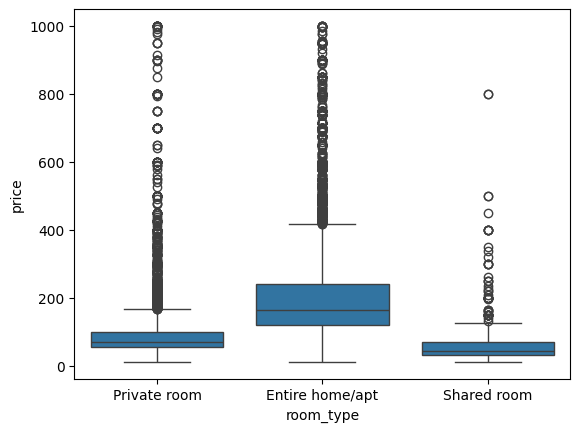

In [ ]:
sns.boxplot(df[df.price < 1000], x="room_type", y="price")

La mas cara es apartamento entero, aproximadamente el doble de habitación privada. La habitación compartida es la de menor precio medio y también la que menos registros de precio elevado

<Axes: xlabel='neighbourhood_group', ylabel='price'>

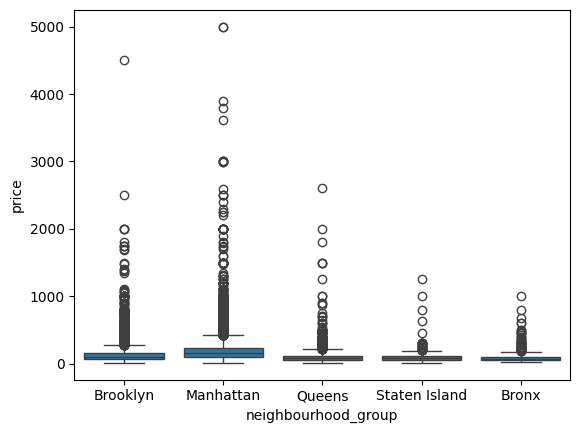

In [ ]:
sns.boxplot(df, x="neighbourhood_group", y="price")

<Axes: xlabel='neighbourhood_group', ylabel='price'>

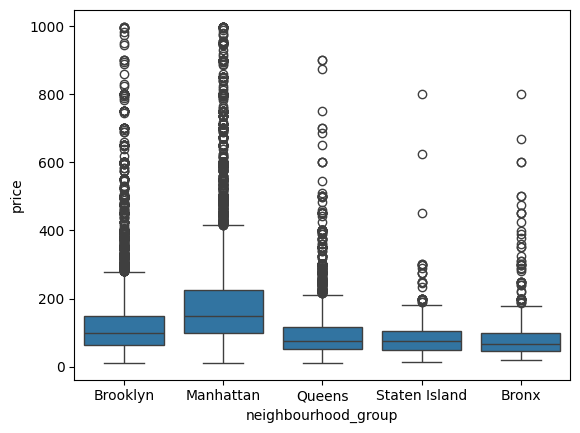

In [ ]:
sns.boxplot(df[df.price < 1000], x="neighbourhood_group", y="price")

Los máximos se encuentran fundamentalmente en Manhattan y también en Brooklyn. Parece razonable

Patrón esperado. Manhattan tiene el precio medio más alto y la mayor cantidad de valores elevados. Le sigue Brooklyn y por último, Queens, Bronx y Staten Island tienen distribuciones similares. En Staten Island parecee haber menos registros, quizá por su separación física del núcleo urbano

<Axes: xlabel='price', ylabel='neighbourhood'>

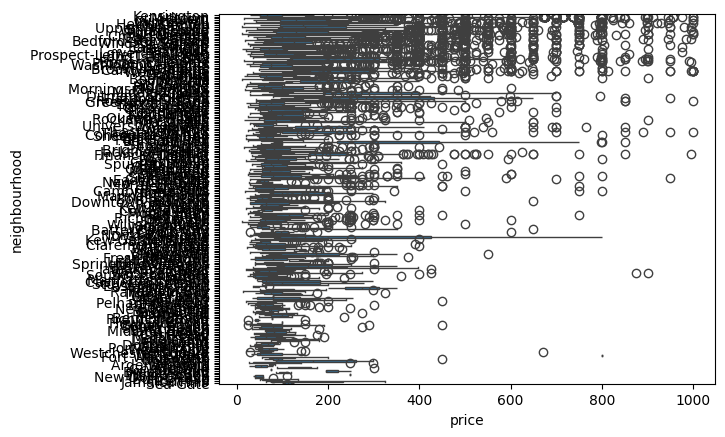

In [ ]:
sns.boxplot(df[df.price < 1000], x="price", y="neighbourhood")

In [ ]:
neigh = df.groupby(["neighbourhood_group", "neighbourhood"])["price"].agg(["count", "mean", "max"]).reset_index()
neigh

,neighbourhood_group,neighbourhood,count,mean,max
0,Bronx,Allerton,37,91.702703,450
1,Bronx,Baychester,6,78.000000,101
2,Bronx,Belmont,17,85.823529,299
3,Bronx,Bronxdale,13,54.923077,100
4,Bronx,Castle Hill,9,63.000000,128
...,...,...,...,...,...
213,Staten Island,Tompkinsville,37,77.567568,245
214,Staten Island,Tottenville,7,144.857143,299
215,Staten Island,West Brighton,17,82.941176,200
216,Staten Island,Westerleigh,2,71.500000,103


<Axes: xlabel='neighbourhood_group', ylabel='mean'>

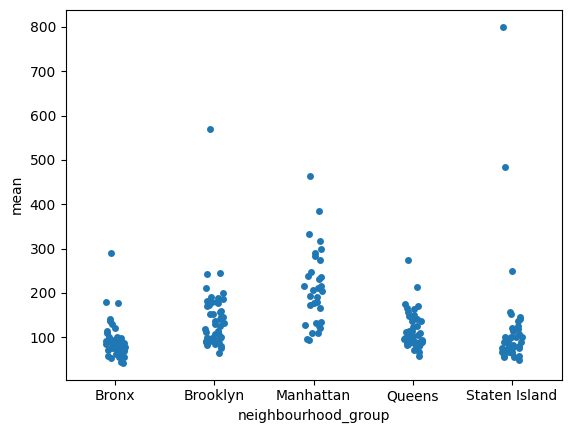

In [ ]:
sns.stripplot(neigh, x="neighbourhood_group", y="mean")

<Axes: xlabel='neighbourhood_group', ylabel='max'>

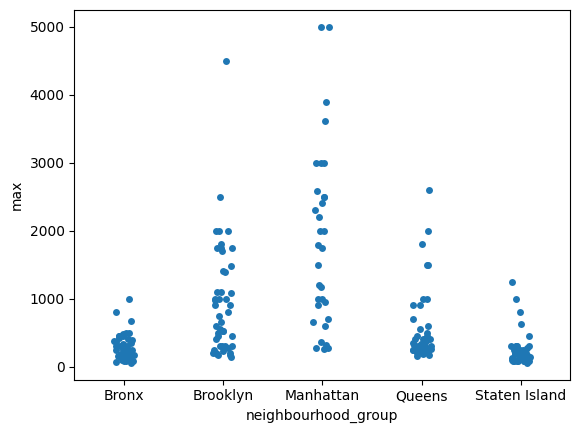

In [ ]:
sns.stripplot(neigh, x="neighbourhood_group", y="max")

<Axes: xlabel='neighbourhood_group', ylabel='count'>

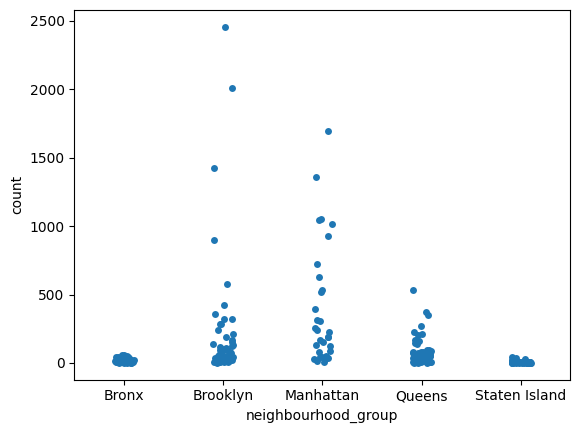

In [ ]:
sns.stripplot(neigh, x="neighbourhood_group", y="count")

In [ ]:
neigh.nlargest(5, columns="mean")

,neighbourhood_group,neighbourhood,count,mean,max
187,Staten Island,Fort Wadsworth,1,800.000000,800
88,Brooklyn,Sea Gate,3,569.666667,1485
202,Staten Island,Prince's Bay,3,484.333333,1250
121,Manhattan,Tribeca,87,464.574713,2400
102,Manhattan,Flatiron District,46,385.260870,1750


In [ ]:
neigh.nlargest(5, columns="max")

,neighbourhood_group,neighbourhood,count,mean,max
105,Manhattan,Harlem,1697,128.469652,5000
116,Manhattan,Nolita,128,275.234375,5000
61,Brooklyn,Clinton Hill,319,182.285266,4500
104,Manhattan,Greenwich Village,193,290.398964,3900
124,Manhattan,Upper West Side,1043,210.743049,3613


# Análisis precio en el mapa

/usr/local/lib/python3.12/dist-packages/pyproj/crs/crs.py:143: FutureWarning: '+init=<authority>:<code>' syntax is deprecated. '<authority>:<code>' is the preferred initialization method. When making the change, be mindful of axis order changes: https://pyproj4.github.io/pyproj/stable/gotchas.html#axis-order-changes-in-proj-6
  in_crs_string = _prepare_from_proj_string(in_crs_string)


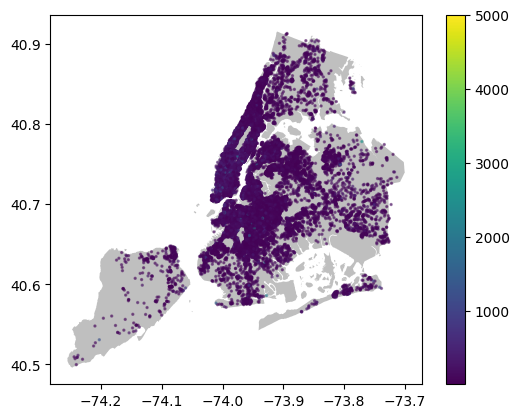

In [ ]:
geometry = [Point(xy) for xy in zip(df.longitude, df.latitude)]

# creamos el GeoPandas dataframe
geo_df = gpd.GeoDataFrame(df,
 crs = crs,
 geometry = geometry)

# dibujamos la silueta del mapa y los puntos por encima
fig, ax = plt.subplots()
street_map.plot(ax=ax, alpha=0.5, color="grey")
geo_df.plot(column="price", ax=ax, alpha=0.5, markersize=2, legend=True)
plt.show()

/usr/local/lib/python3.12/dist-packages/pyproj/crs/crs.py:143: FutureWarning: '+init=<authority>:<code>' syntax is deprecated. '<authority>:<code>' is the preferred initialization method. When making the change, be mindful of axis order changes: https://pyproj4.github.io/pyproj/stable/gotchas.html#axis-order-changes-in-proj-6
  in_crs_string = _prepare_from_proj_string(in_crs_string)


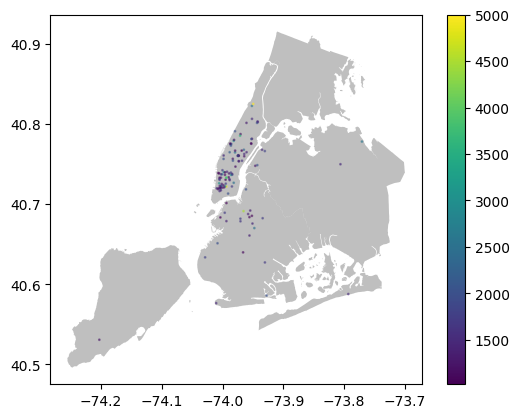

In [ ]:
geometry = [Point(xy) for xy in zip(df[df.price > 1000].longitude,
                                    df[df.price > 1000].latitude)]

# creamos el GeoPandas dataframe
geo_df = gpd.GeoDataFrame(df[df.price > 1000],
 crs = crs,
 geometry = geometry)

# dibujamos la silueta del mapa y los puntos por encima
fig, ax = plt.subplots()
street_map.plot(ax=ax, alpha=0.5, color="grey")
geo_df.plot(column="price", ax=ax, alpha=0.5, markersize=1, legend=True)
plt.show()

Supercandidatos

In [ ]:
supercandidates = df.loc[(df.room_type == "Entire home/apt") &
 (df.neighbourhood_group == "Manhattan") &
  (df.reviews_per_month < 3), "price"]

In [ ]:
print(f"El precio medio de los super candidatos es {supercandidates.mean()}")
print(f"El precio medio del resto es {df.loc[~df.index.isin(supercandidates.index), 'price'].mean()}")

El precio medio de los super candidatos es 257.0796652200868
El precio medio del resto es 124.93623948247432


Qué barrio tiene los apartamentos más caros en relación a su boro
(distrito)? Cuál tiene el más caro?

In [ ]:
# Usamos window functions (groupby.transform en pandas)

df["price_ratio"] = df.groupby("neighbourhood_group")["price"].transform(lambda x: x/x.mean())

In [ ]:
df

,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,price_ratio
0,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,0.21,6,365,1.157052
1,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,0.38,2,355,1.122617
2,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,0.00,1,365,0.748411
3,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,4.64,1,194,0.691125
4,Manhattan,Murray Hill,40.74767,-73.97500,Entire home/apt,200,3,74,0.59,1,129,0.997882
...,...,...,...,...,...,...,...,...,...,...,...,...
30098,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70,2,0,0.00,2,9,0.543582
30099,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40,4,0,0.00,2,36,0.310618
30100,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115,10,0,0.00,1,27,0.573782
30101,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55,1,0,0.00,6,2,0.274417


Análisis por neighborhood dentro de cada neighborhood group

In [ ]:
df.groupby("neighbourhood")["price_ratio"].mean().sort_values(ascending=False)

,price_ratio
neighbourhood,
Fort Wadsworth,8.031833
Prince's Bay,4.862606
Sea Gate,4.423719
Riverdale,3.354791
Neponsit,2.730762
...,...
Borough Park,0.507458
Mount Eden,0.491641
Port Richmond,0.489942


In [ ]:
df.sort_values("price_ratio", ascending=False)

,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,price_ratio
3026,Brooklyn,Clinton Hill,40.69127,-73.96563,Entire home/apt,4500,1,5,0.09,11,365,34.944536
24575,Queens,Bayside,40.77811,-73.77069,Entire home/apt,2600,6,3,1.73,1,362,25.849443
2035,Manhattan,Nolita,40.72193,-73.99379,Entire home/apt,5000,1,2,0.03,1,365,24.947040
21310,Manhattan,Harlem,40.82511,-73.94961,Entire home/apt,5000,1,2,0.38,2,150,24.947040
28613,Queens,Long Island City,40.74869,-73.94294,Entire home/apt,2000,1,0,0.00,1,365,19.884187
...,...,...,...,...,...,...,...,...,...,...,...,...
5110,Manhattan,Harlem,40.82159,-73.95013,Private room,16,2,43,1.66,3,154,0.079831
3181,Manhattan,Upper East Side,40.76866,-73.95553,Entire home/apt,16,2,21,1.69,1,9,0.079831
29224,Manhattan,Hell's Kitchen,40.76279,-73.99463,Entire home/apt,15,2,0,0.00,1,139,0.074841
14622,Manhattan,Chelsea,40.74045,-74.00047,Private room,12,3,8,0.59,1,37,0.059873


Top 3 apartamentos más caros (en proporción relativa) en su barrio

In [ ]:
df.nlargest(3, columns="price_ratio").merge(apartment_details, left_index=True, right_index=True)

,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,price_ratio,name,host_name,host_id
3026,Brooklyn,Clinton Hill,40.69127,-73.96563,Entire home/apt,4500,1,5,0.09,11,365,34.944536,Sweet Apartment on Quiet Block,Liz,367815
24575,Queens,Bayside,40.77811,-73.77069,Entire home/apt,2600,6,3,1.73,1,362,25.849443,Great location-Close to metro in cool neighbor...,Roberto,81160897
2035,Manhattan,Nolita,40.72193,-73.99379,Entire home/apt,5000,1,2,0.03,1,365,24.947040,Central Pk West-Convenient 1 BR,Joy,4848828
